# Guerrero's nonzero difference mean

The general published PLS penalty is

$
\|y-\tau\|_2^2+\lambda\|D_d\tau-\mu\mathbf{1}\|_2^2.
$ Holding $\mu$ fixed is distinct from inserting Guerrero's observed-difference plug-in $\widehat{\mu}=\operatorname{mean}(D_dy)$.

In [1]:
import awesomefigures as af
from matplotlib_inline.backend_inline import set_matplotlib_formats

# Publication styling only; numerical estimates and metrics are unchanged.
af.set_style("elegante", font="DejaVu Sans", use_tex=False,
             palette="okabe-ito", rasterize=False)
set_matplotlib_formats("svg", "png")

from trendestimation._docs_style import apply_documentation_figure_style
apply_documentation_figure_style()


## Illustrate a trending signal

When $d=1$ and $\mu\approx\text{slope}$, a strong penalty preserves a fitted line with the specified increment; $\mu=0$ instead penalizes all slope.

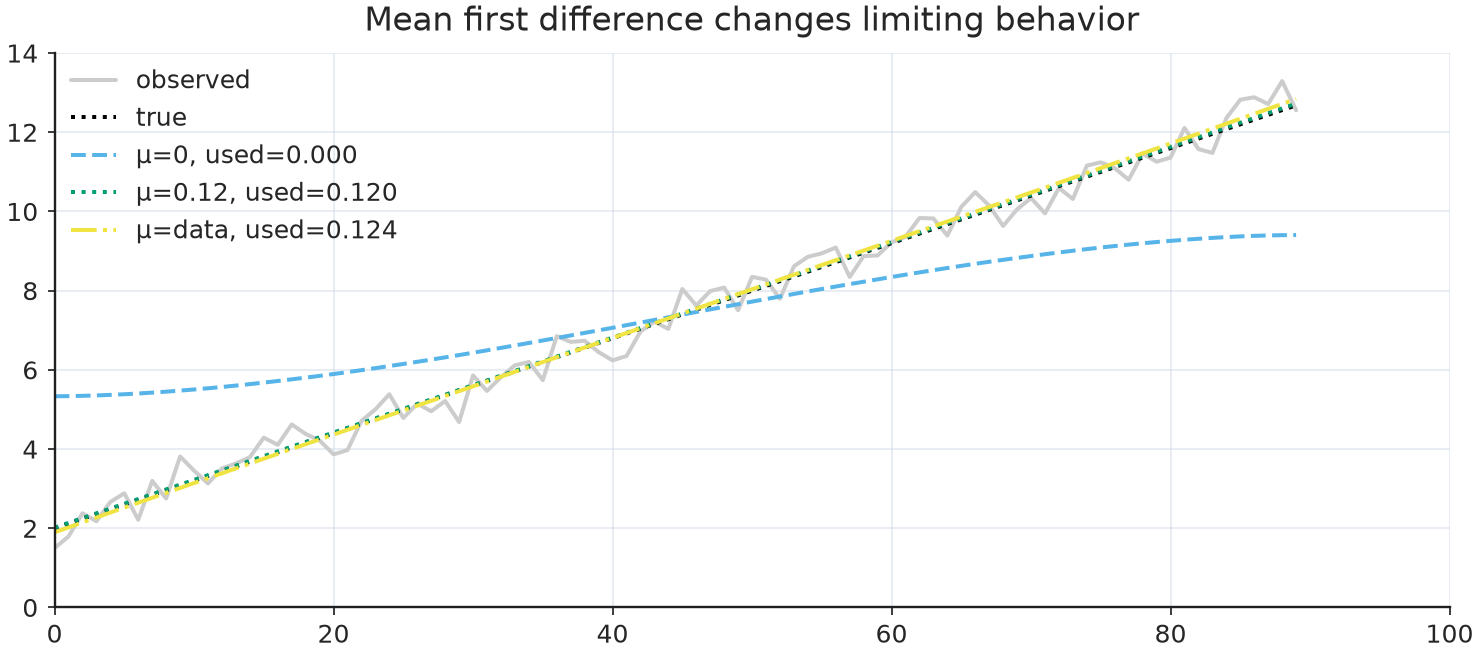

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from trendestimation import TrendSmoother
rng=np.random.default_rng(15);t=np.arange(90)
truth=2+.12*t;y=truth+rng.normal(0,.35,len(t))
sm=TrendSmoother(len(y),order=1)
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(y,color="0.8",label="observed");ax.plot(truth,"k:",label="true")
for mu in [0,.12,"data"]:
    f=sm.fit(y,lambda_=1000,mu=mu)
    ax.plot(f.trend,label=f"μ={mu}, used={f.mu:.3f}")
ax.set(title="Mean first difference changes limiting behavior");ax.legend();plt.show()

## Affine null-space limit

At $\lambda=\infty$, $D_d\tau=\mu\mathbf{1}$.  For $d=2$, a nonzero $\mu$ generates quadratic curvature instead of the linear null-space trend associated with $\mu=0$.

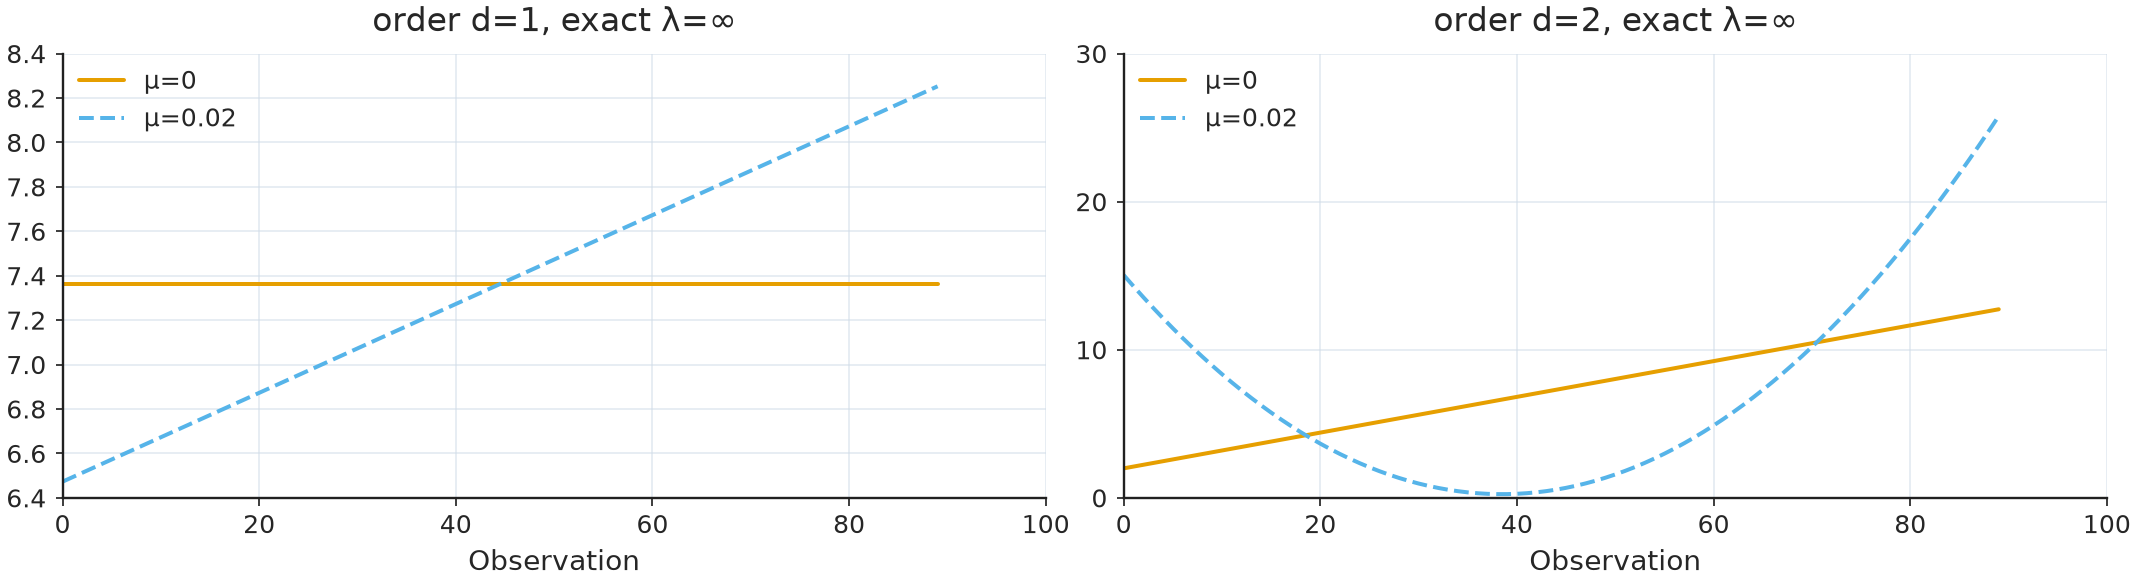

In [3]:
fig,axs=plt.subplots(1,2,figsize=(12,3.5))
for a,d in zip(axs,[1,2]):
    model=TrendSmoother(len(y),d)
    for mu in [0,.02]:
        fitted=model.fit(y,lambda_=float("inf"),mu=mu)
        a.plot(fitted.trend,label=f"μ={mu}")
        assert np.max(np.abs(model.D@fitted.trend-mu))<1e-6
    a.set(title=f"order d={d}, exact λ=∞",xlabel="Observation");a.legend()
fig.tight_layout();plt.show()

## Conditional EDF and limits

The displayed $\mathrm{EDF}=\operatorname{tr}(H_\lambda)$ conditions on $\mu$. It is not the full EDF of the estimator if $\mu$ was selected from the same sample; classical selectors in this release require fixed numeric $\mu$.

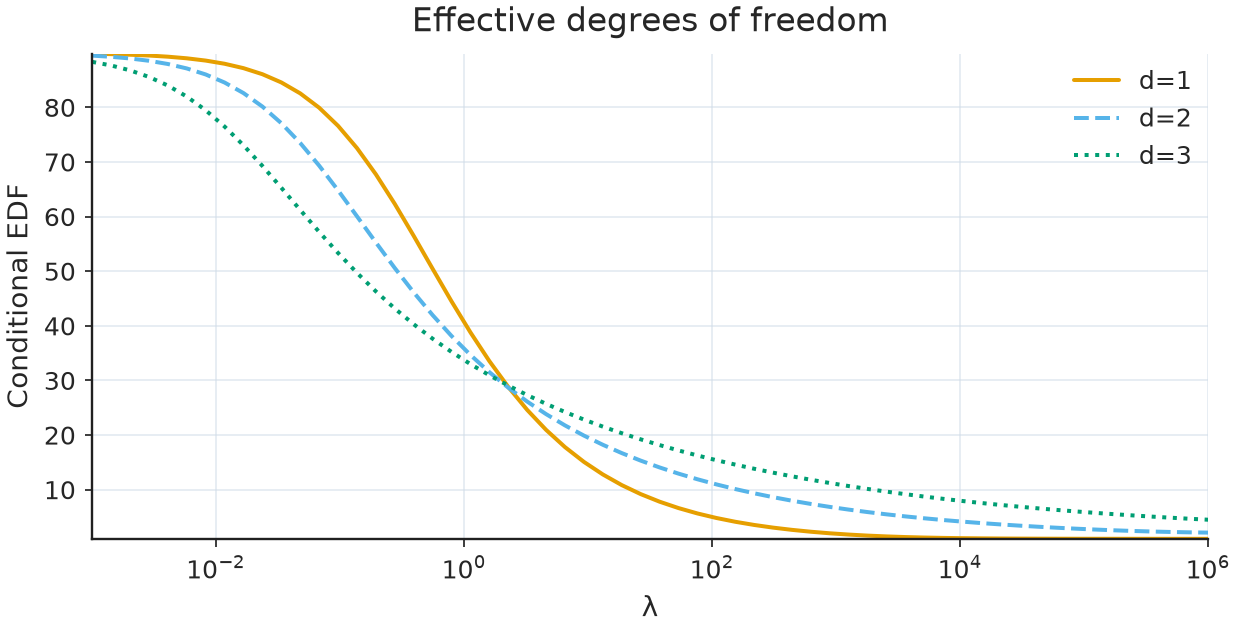

μ='data' is allowed for fitting, not for fixed-μ CV/GCV/AICc/BIC selection.


In [4]:
s=np.geomspace(.001,1e6,60)
fig,ax=plt.subplots(figsize=(8,3.5))
for d in [1,2,3]:
    model=TrendSmoother(len(y),d)
    ax.semilogx(s,[model.degrees_of_freedom(float(v)) for v in s],label=f"d={d}")
ax.set(xlabel="λ",ylabel="Conditional EDF",title="Effective degrees of freedom")
ax.legend();plt.show()
print("μ='data' is allowed for fitting, not for fixed-μ CV/GCV/AICc/BIC selection.")

## Difference-mean plug-in with Gaussian MLE

The mode `mu="data"` uses the **sample average of the observed (d)-th differences**, `np.mean(D_d @ y)`. In Gaussian MLE, the likelihood conditions on this plug-in; it is **not** a joint maximum-likelihood estimate of `mu`, `lambda`, and the variances. The two variance components measure independent observation noise and the latent centered differences—not the variance of the original series or of its fitted trend.

Empirical first-difference mean: 0.124229
Selected MLE lambda: 199.05
Observation-noise variance: 0.12414
Latent first-difference variance: 0.00062366
These are conditional Gaussian model estimates, not residual MSE.


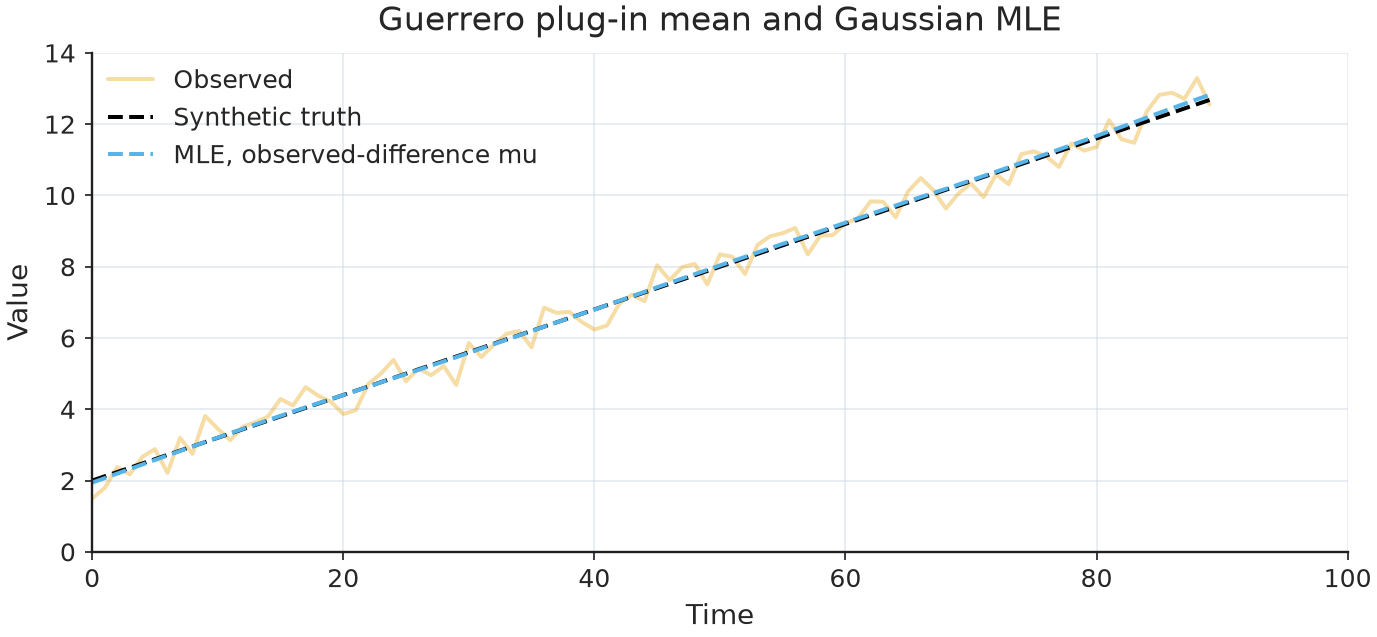

In [5]:
from trendestimation import select_lambda, estimate_variance_components

solver = TrendSmoother(len(y), order=1)
difference_mean = float(np.mean(solver.D @ y))
selected = select_lambda(solver, y, criterion="mle", mu="data")
components = estimate_variance_components(
    solver, y, lambda_=selected.lambda_, mu="data"
)
np.testing.assert_allclose(components.mu, difference_mean)
print(f"Empirical first-difference mean: {components.mu:.6f}")
print(f"Selected MLE lambda: {selected.lambda_:.5g}")
print(f"Observation-noise variance: {components.observation_variance:.5g}")
print(f"Latent first-difference variance: {components.difference_variance:.5g}")
print("These are conditional Gaussian model estimates, not residual MSE.")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(y, "-", alpha=0.35, label="Observed")
ax.plot(truth, "k--", label="Synthetic truth")
ax.plot(solver.fit(y, lambda_=selected.lambda_, mu="data").trend,
        label="MLE, observed-difference mu")
ax.set(xlabel="Time", ylabel="Value", title="Guerrero plug-in mean and Gaussian MLE")
ax.legend()
plt.show()

## Matched penalty and smoothness score plots

For the current notebook data (or a labeled synthetic fallback), compare CV, GCV, AICc and BIC versus $\lambda$ **and** $S(\lambda)$; the mapped grids have identical candidate penalties. Each execution saves inline SVG and PNG figures. The single GCV selector timing is illustrative and is **not** a controlled speed comparison; use the separate multi-seed benchmark for that.

Paired coordinates: last 60 observations of the notebook series; n=60, d=2, mu=0
Normalized S grid: [0.       0.1      0.2      0.3      0.4      0.5      0.6      0.7
 0.8      0.9      0.95     0.99     0.999    0.9999   0.999999 1.      ]
S=0 maps to lambda=0; S=1 maps to lambda=+infinity.
Near-1 targets: S=0.950000 -> lambda=886.169, S=0.990000 -> lambda=33003.8, S=0.999000 -> lambda=510198, S=0.999900 -> lambda=5.29957e+06, S=0.999999 -> lambda=5.32145e+08
Maximum inversion / round-trip error: 1.33e-15


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


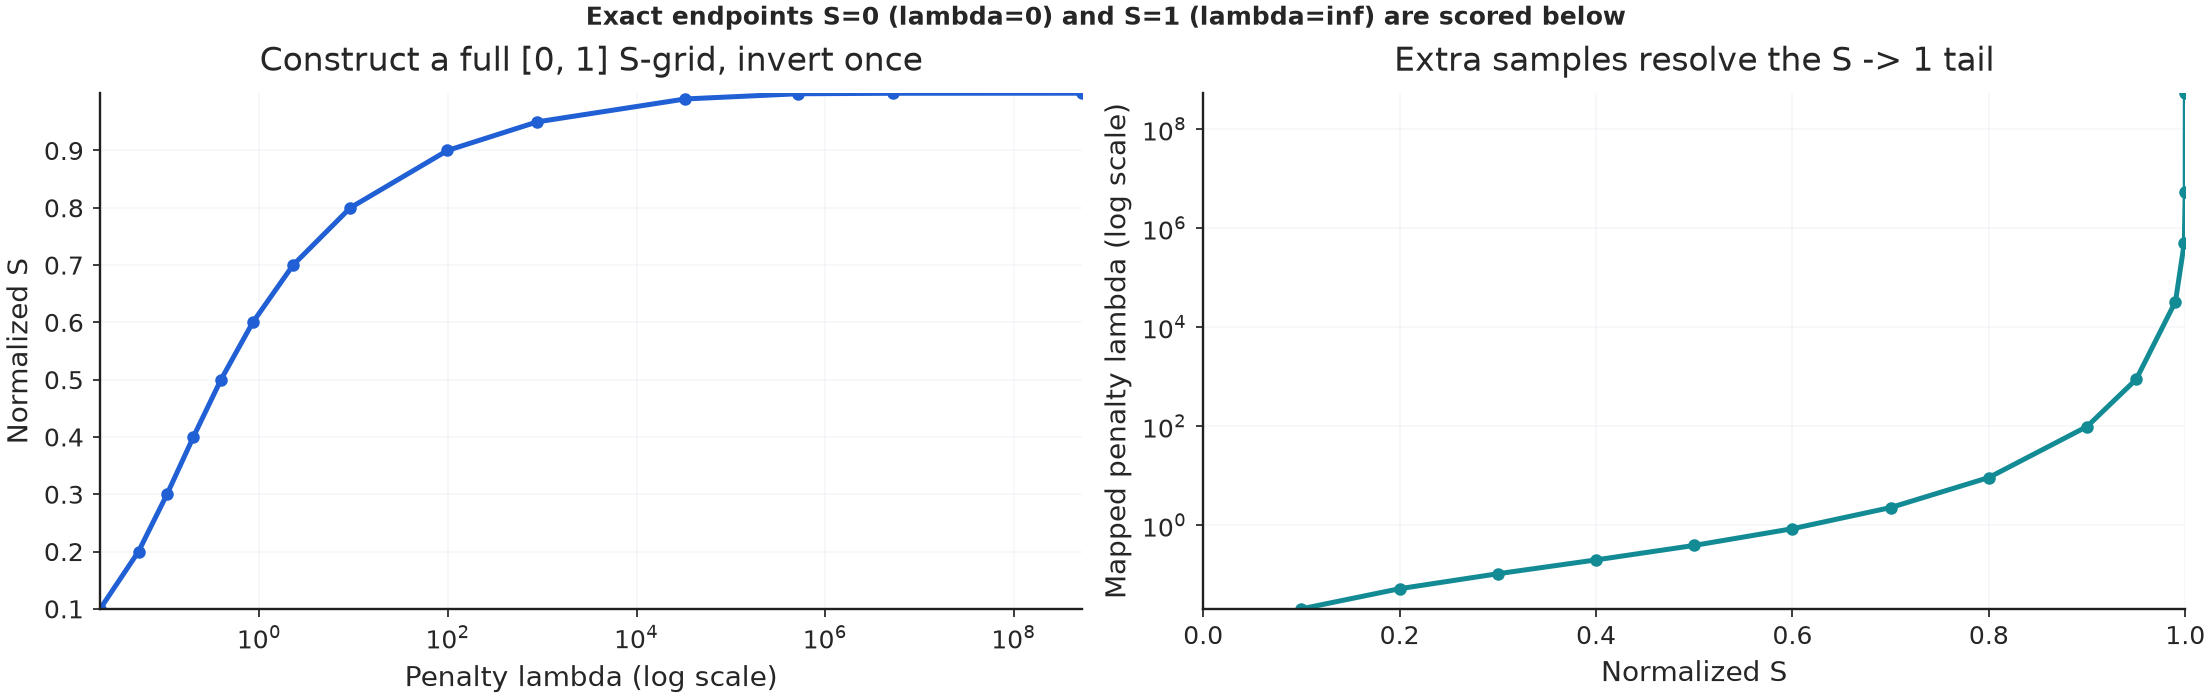

  CV: lambda=    886.169, S=0.95, score=0.128982
 GCV: lambda=    886.169, S=0.95, score=0.128341
AICC: lambda=        inf, S=1, score=-2.02959
 BIC: lambda=  0.0205109, S=0.1, score=-2.75268


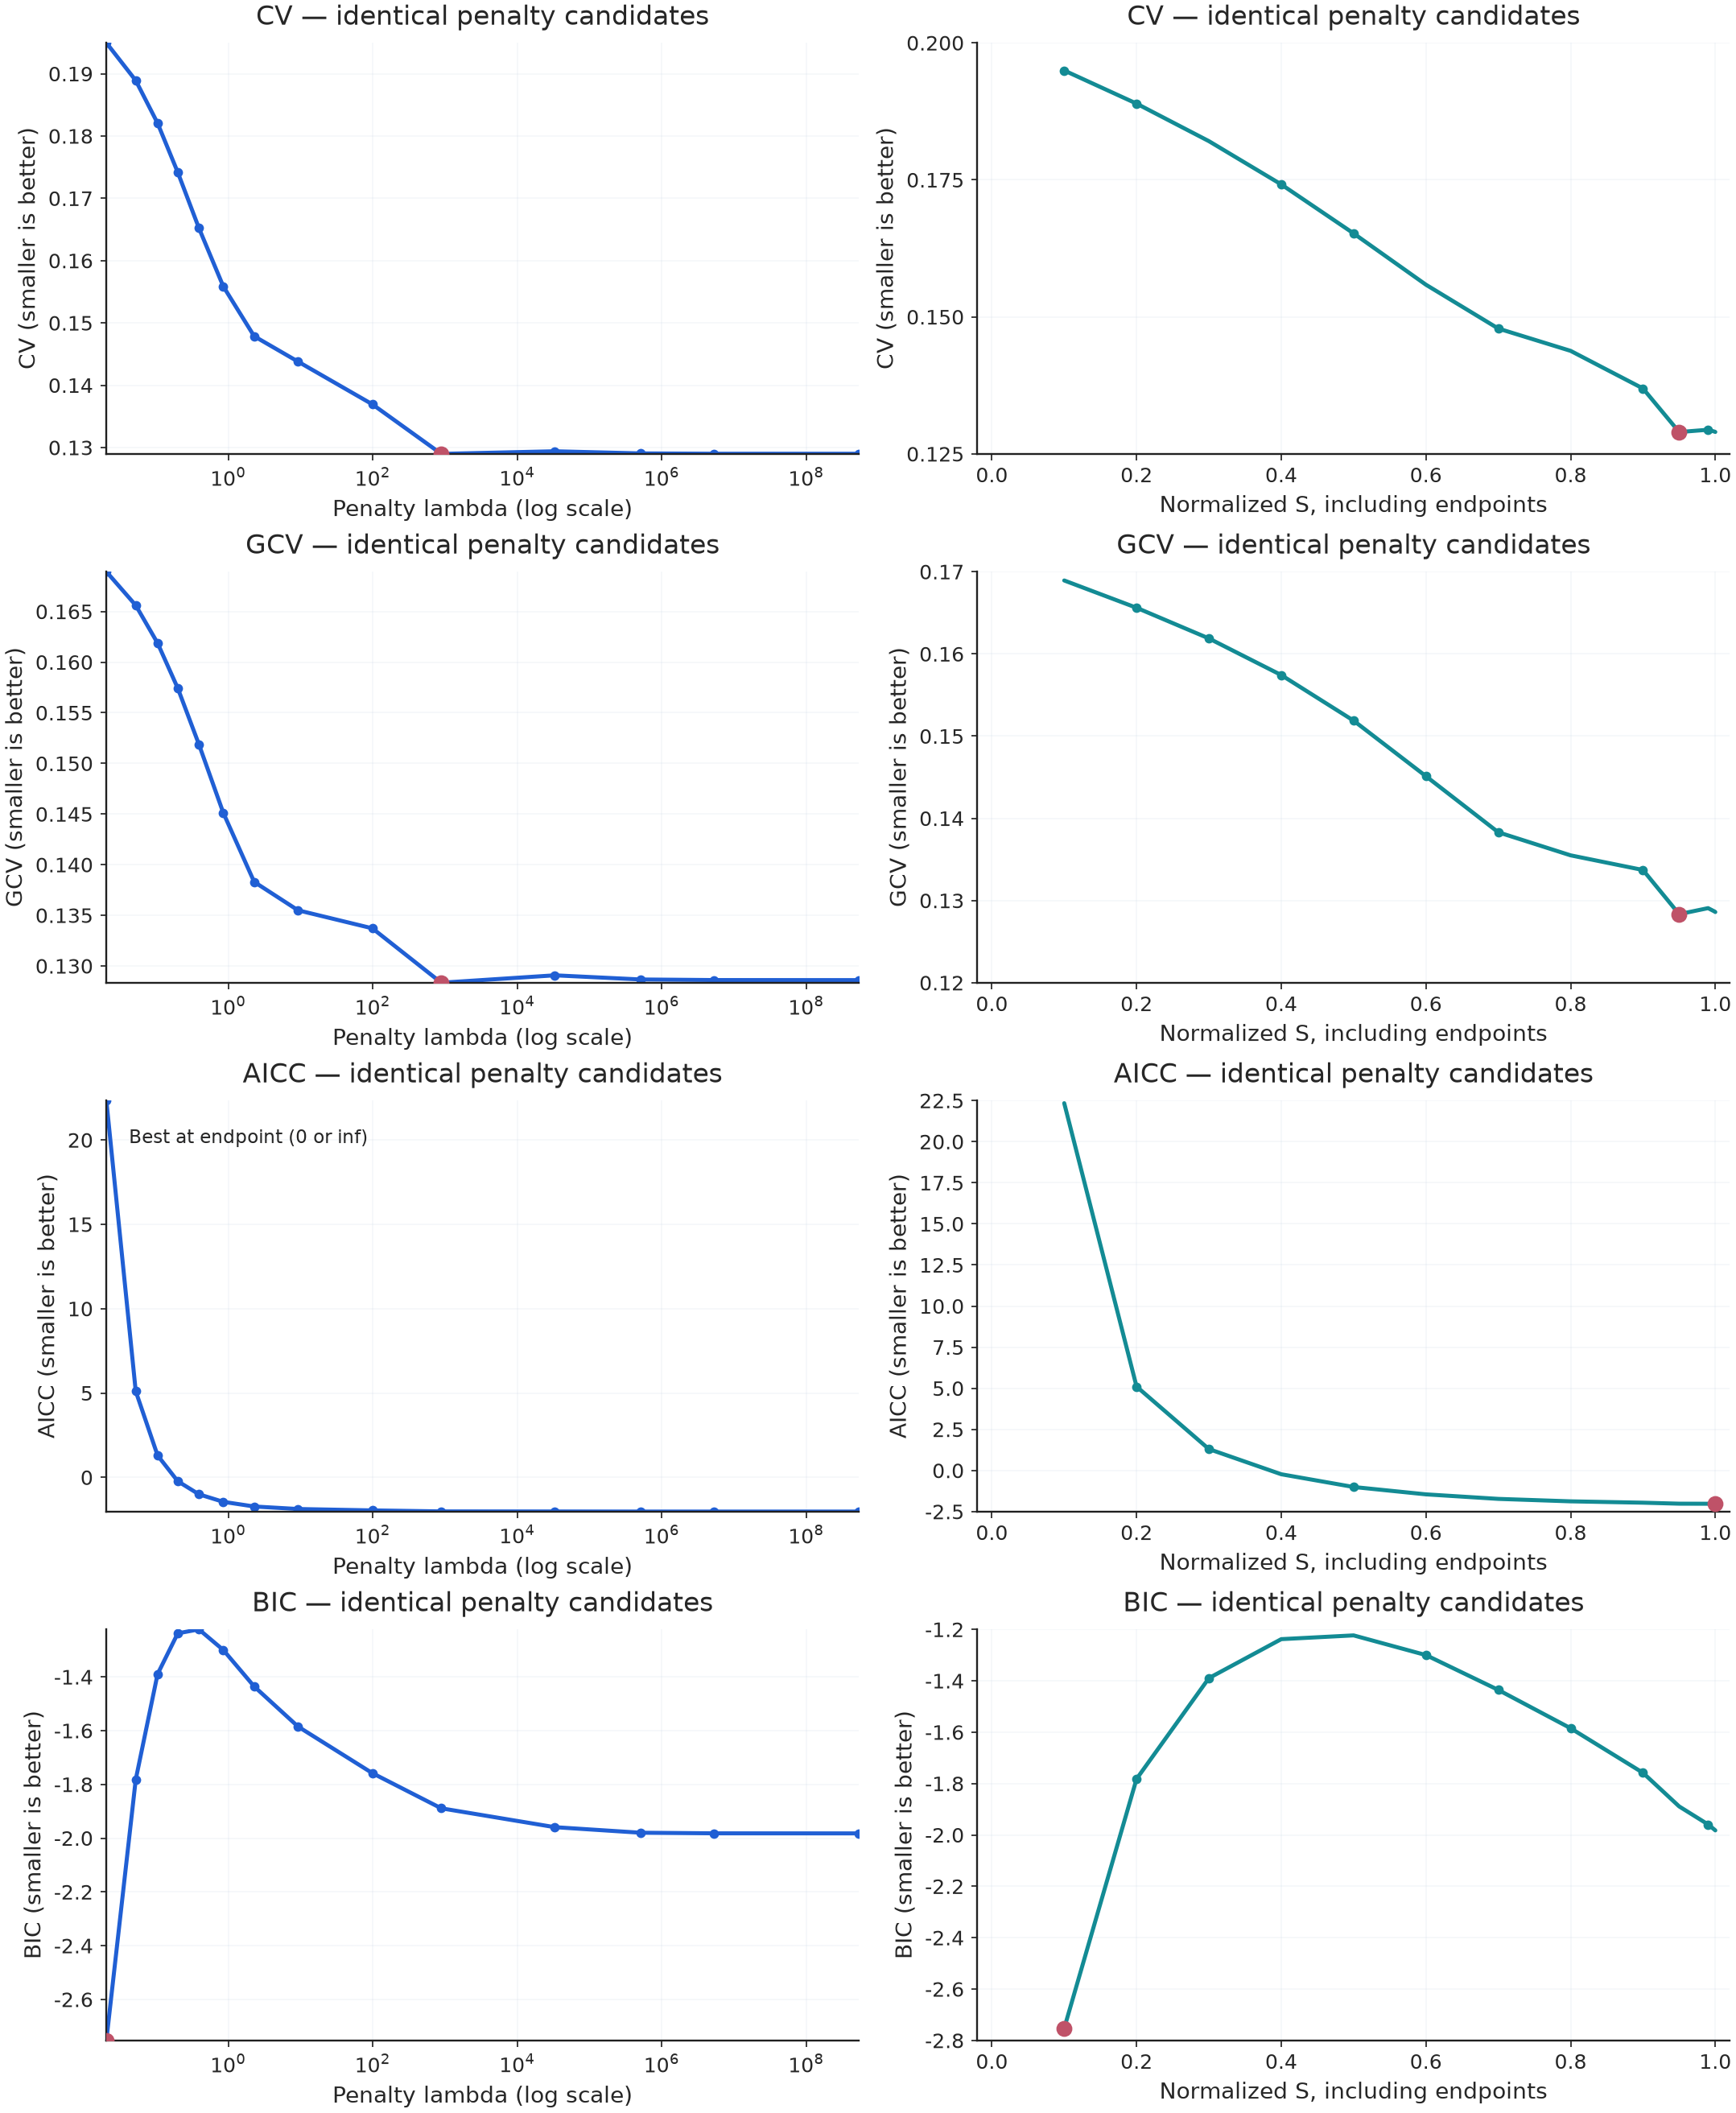

Left log-lambda plots omit 0 and infinity as coordinates, NOT as evaluated candidates. Right S plots include those endpoints. CV can be infinite at S=0 because unregularized LOOCV is undefined.


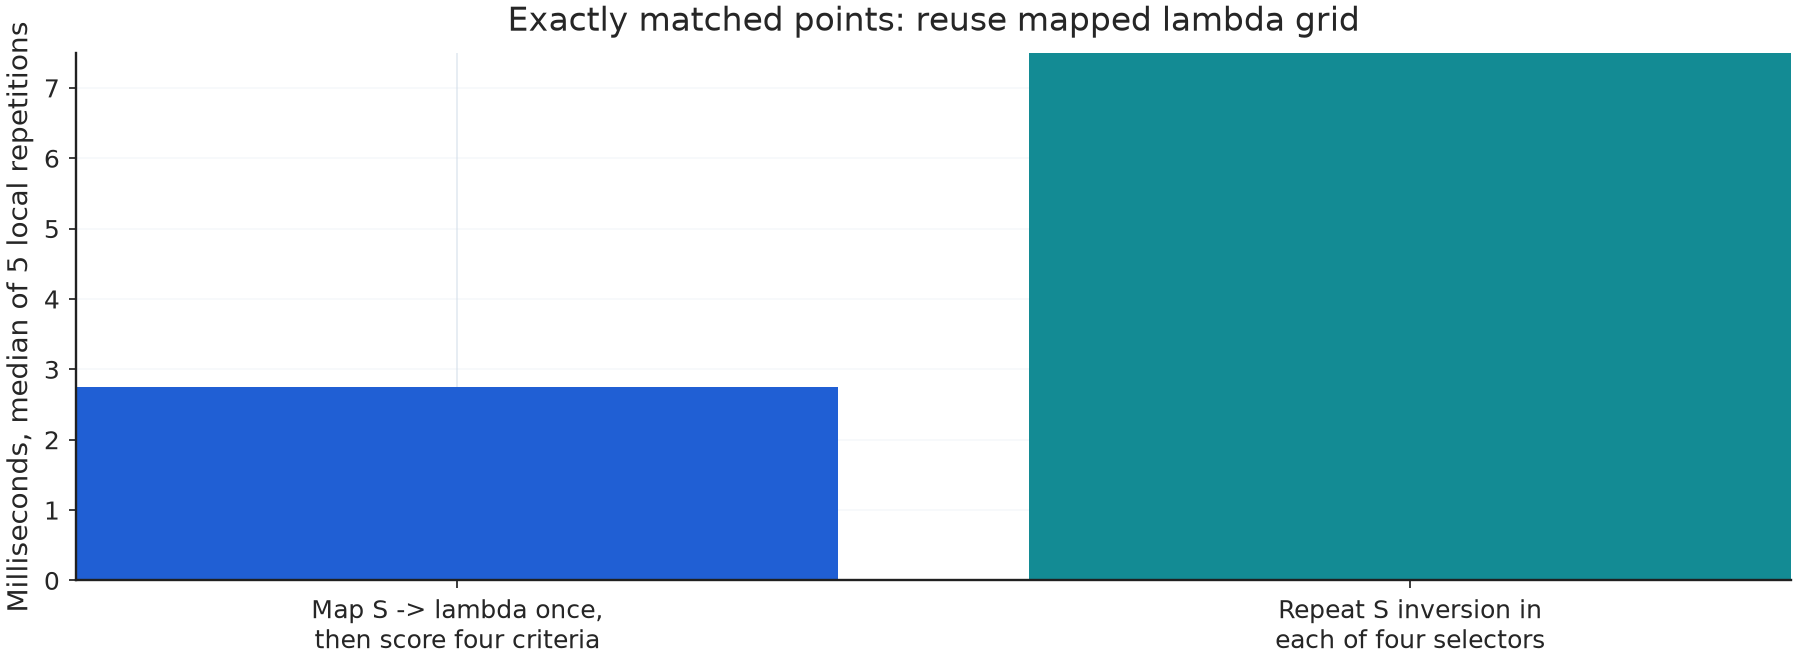

Four-criterion sweep, lambda-map-once: 2.743 ms; direct S selector (repeated mapping): 7.493 ms.
Both evaluate the same 16 penalties. This small, single-session measurement isolates a reusable-grid workflow, not the general speed of every optimization method or back end.


In [6]:
from trendestimation._docs_coordinates import show_dual_coordinate_gallery

_coordinate_series = next((globals()[name] for name in
                           ("history", "y", "observed", "series")
                           if name in globals()), None)
show_dual_coordinate_gallery(_coordinate_series, order=2, mu=0.0)
